Part a

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Setting the random seed (special to be reproducibile)
random.seed(69)
np.random.seed(69)

def generate_random_graph(num_nodes, p):
    # Creating an adjacency list of the graph
    graph = {i: [] for i in range(num_nodes)}
    
    # Adding all edges with probability p
    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):
            if random.random() < p:
                graph[i].append(j)
                graph[j].append(i)
    return graph

def find_largest_connected_component(graph):
    visited = set()
    
    def dfs(node):
        stack = [node]
        component = []
        while stack:
            current = stack.pop()
            if current not in visited:
                visited.add(current)
                component.append(current)
                stack.extend(graph[current])
        return component
    
    largest_cc = []
    for node in graph:
        if node not in visited:
            component = dfs(node)
            if len(component) > len(largest_cc):
                largest_cc = component
    
    return len(largest_cc)

def simulate_er_graphs(num_nodes, p_values):
    largest_component_sizes = []  
    avg_degrees = [] 
    
    for p in p_values:
        G = generate_random_graph(num_nodes, p)
        largest_cc_size = find_largest_connected_component(G)
        # Storing the size of the largest component and the average degree of the graph (Relative size)
        largest_component_sizes.append(largest_cc_size / num_nodes)
        # Calculating the average degree
        avg_degrees.append(p * (num_nodes - 1))  
    
    return avg_degrees, largest_component_sizes

avg_degrees_list = []
largest_component_sizes_list = []

#Consider different number of nodes and probabilities to generate various average degrees.
num_nodes_list = [100, 500, 1000]
p_values = np.linspace(0.01, 0.05, 100)
for num_nodes in num_nodes_list:
    avg_degrees, largest_component_sizes = simulate_er_graphs(num_nodes, p_values)
    avg_degrees_list.append(avg_degrees)
    largest_component_sizes_list.append(largest_component_sizes)


Part b

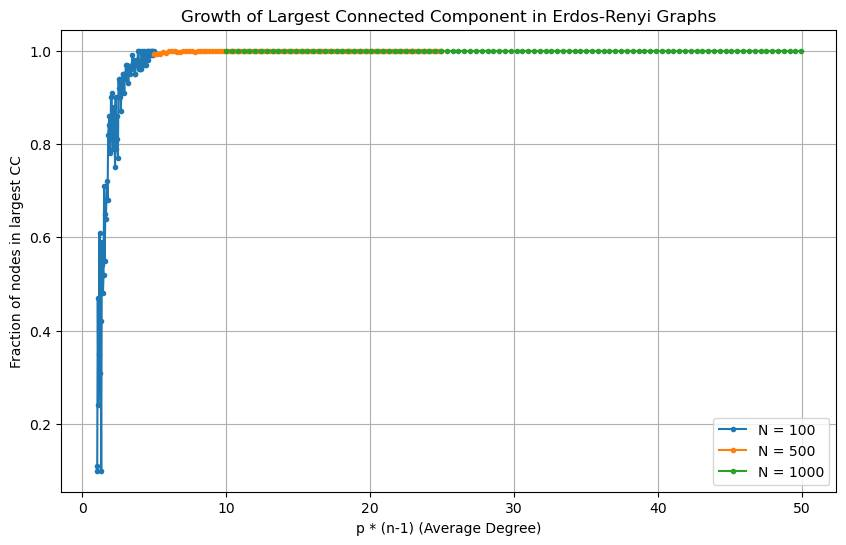

In [2]:
def plot_largest_component(avg_degrees_list, largest_component_sizes_list, num_nodes_list):
    plt.figure(figsize=(10, 6))
    
    for avg_degrees, largest_component_sizes, num_nodes in zip(avg_degrees_list, largest_component_sizes_list, num_nodes_list):
        # Plotting the size of the largest connected component relative to the average degree
        plt.plot(avg_degrees, largest_component_sizes, label=f'N = {num_nodes}', marker='o', linestyle='-', markersize=3)
    
    plt.xlabel('p * (n-1) (Average Degree)')
    plt.ylabel('Fraction of nodes in largest CC')
    plt.title('Growth of Largest Connected Component in Erdos-Renyi Graphs')
    plt.legend()
    plt.grid(True) 
    plt.show()

plot_largest_component(avg_degrees_list, largest_component_sizes_list, num_nodes_list)

Part c

In [3]:
def report_phase_transition(avg_degrees_list, largest_component_sizes_list, num_nodes_list):
    for avg_degrees, largest_component_sizes, num_nodes in zip(avg_degrees_list, largest_component_sizes_list, num_nodes_list):
        print(f"\nFor N = {num_nodes}:") 
        for avg_deg, size in zip(avg_degrees, largest_component_sizes):
            # Finding the point where the largest component size reaches 50% of all nodes (phase transition)
            if size >= 0.5:
                print(f"  Phase transition observed around average degree ~{avg_deg:.2f} (p = {avg_deg / (num_nodes - 1):.4f})")
                break

report_phase_transition(avg_degrees_list, largest_component_sizes_list, num_nodes_list)



For N = 100:
  Phase transition observed around average degree ~1.19 (p = 0.0120)

For N = 500:
  Phase transition observed around average degree ~4.99 (p = 0.0100)

For N = 1000:
  Phase transition observed around average degree ~9.99 (p = 0.0100)
